# Where the axis fires (segments, CoT, tokens, eval transcripts)

Where along a conversation the axis responds: segments, chain-of-thought, role tags, and evaluation transcripts.

## 1. Setup

Install dependencies, locate or clone the repository, and load the frozen axis.

In [1]:
%pip install -q -U huggingface_hub datasets

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 784.9/784.9 kB 49.5 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 559.1/559.1 kB 52.8 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 4.5/4.5 MB 143.9 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 50.1/50.1 MB 56.9 MB/s eta 0:00:00:00:0100:01


In [ ]:
import os, sys

REPO = "asherk7/human-ai"


def get_secret(name):
    """Read a token from the environment or Colab secrets; prompt as a last resort."""
    if os.environ.get(name):
        return os.environ[name]
    try:
        from google.colab import userdata
        val = userdata.get(name)
        if val:
            return val
    except Exception:
        pass
    import getpass
    return getpass.getpass(f"Paste your {name}: ")


REPO_ROOT = next((os.path.abspath(c) for c in (".", "..", "../..", "human-ai")
                  if os.path.isdir(os.path.join(c, "src"))), None)
if REPO_ROOT is None:
    !git clone -q --depth 1 https://github.com/{REPO}.git
    REPO_ROOT = os.path.abspath("human-ai")
sys.path.insert(0, REPO_ROOT)
print("repo root:", REPO_ROOT)

In [3]:
import json, random, re
from pathlib import Path

import numpy as np
import pandas as pd
import torch
import matplotlib.pyplot as plt

from src.model import load_model
from src.activations import NEUTRAL_SYS, build_chat_inputs, sanitize_messages
from src.analysis import bootstrap_auc

SEED = 42
random.seed(SEED); np.random.seed(SEED); torch.manual_seed(SEED)

STEER_LAYER, REPORT_LAYER, PROBE_LAYER = 13, 27, 33
SAVE_LAYERS = [13, 27, 33]

MODEL_ID = "google/gemma-3-4b-it"

try:
    from google.colab import drive
    drive.mount("/content/drive")
    _base = Path("/content/drive/MyDrive")
    OUT = _base / "firing_artifacts"
except ModuleNotFoundError:
    OUT = Path(REPO_ROOT) / "artifacts" / "human-AI" / "firing"
OUT.mkdir(parents=True, exist_ok=True)
print(f"outputs -> {OUT}")

Mounted at /content/drive
outputs -> /content/drive/MyDrive/firing_artifacts


In [4]:
from huggingface_hub import login

login(get_secret("HF_TOKEN"))

bundle = load_model(MODEL_ID)
model, tok = bundle["model"], bundle["tokenizer"]
N_LAYERS, HIDDEN = bundle["n_layers"], bundle["hidden_size"]
ALL_LAYERS = list(range(N_LAYERS))
DEV = next(model.parameters()).device
print(f"{bundle['model_id']}: {N_LAYERS} layers, hidden {HIDDEN}, on {DEV}")

config.json:   0%|          | 0.00/855 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/1.16M [00:00<?, ?B/s]

tokenizer.json: reconstructing file:   0%|          |  0.00B / 33.4MB            

tokenizer.json: downloading bytes:           |  0.00B            

added_tokens.json:   0%|          | 0.00/35.0 [00:00<?, ?B/s]

special_tokens_map.json:   0%|          | 0.00/662 [00:00<?, ?B/s]

... (3 outputs left out)

Fetching 2 files:   0%|          | 0/2 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/883 [00:00<?, ?it/s]

generation_config.json:   0%|          | 0.00/215 [00:00<?, ?B/s]

google/gemma-3-4b-it: 34 layers, hidden 2560, on cuda:0


In [5]:
AXIS_PATH = Path(REPO_ROOT) / "artifacts" / "human-AI" / "axis" / "human_ai_axis_gemma3_4b_v2.pt"
art = torch.load(AXIS_PATH, map_location="cpu", weights_only=False)
assert art["model_id"] == MODEL_ID, art["model_id"]
axis_unit, midpoint = art["axis_unit"], art["midpoint"]

GAP = {L: float(art["axis"][L].norm()) for L in ALL_LAYERS}
pcols = [f"proj_{L}" for L in SAVE_LAYERS]

def gaps(x, layer):
    """Raw self-axis units -> persona-gap units."""
    return x / GAP[layer]

print(f"self axis {art.get('axis_version', '?')} | persona gap:",
      {L: round(GAP[L], 1) for L in SAVE_LAYERS})

self axis v2 | persona gap: {13: 1069.7, 27: 2253.3, 33: 47.8}


In [6]:
TOOL_RE = re.compile(r"<tool_use:\w+>.*?(?:</tool_use:\w+>|\Z)", re.DOTALL)

@torch.no_grad()
def _frame_from_string(s, intervals, layers=None):
    """Score a raw string. intervals: [(char_a, char_b, msg_idx, role, segment)];
    later intervals override earlier ones, so sub-spans go after their message.
    Tokens outside every interval read segment 'template' -- including <bos>,
    which fixes the old tag classifier's known wart by construction.
    Returns a DataFrame: token, pos, msg_idx, role, segment, proj_<L>.
    """
    layers = SAVE_LAYERS if layers is None else layers
    enc = tok(s, return_offsets_mapping=True, return_tensors="pt",
              add_special_tokens=False)
    ids = enc["input_ids"]
    assert ids.shape[1] < 8192, f"sequence too long: {tuple(ids.shape)}"
    out = model(ids.to(DEV), output_hidden_states=True)
    projs = {L: ((out.hidden_states[L + 1][0].float().cpu() - midpoint[L])
                 @ axis_unit[L]).tolist() for L in layers}
    rows = []
    for pos, (t, (ca, cb)) in enumerate(zip(tok.convert_ids_to_tokens(ids[0]),
                                            enc["offset_mapping"][0].tolist())):
        mi, role, seg = -1, "none", "template"
        for a, b, i, r, name in intervals:
            if a <= ca < b:
                mi, role, seg = i, r, name
        row = {"token": t, "pos": pos, "msg_idx": mi, "role": role, "segment": seg}
        for L in layers:
            row[f"proj_{L}"] = projs[L][pos]
        rows.append(row)
    return pd.DataFrame(rows)

def token_frame(messages, sub_spans=None, layers=None):
    """Frame over a templated conversation (template-safe messages; run
    sanitize_messages first for third-party transcripts). sub_spans:
    {msg_idx: [(name, a, b)]} with char offsets into that message's *stripped*
    content (the template trims content); unlabeled content keeps the message
    role as its segment."""
    s = tok.apply_chat_template(messages, add_generation_prompt=False,
                                tokenize=False)
    intervals, cursor = [], 0
    for mi, m in enumerate(messages):
        content = m["content"].strip()
        a = s.find(content, cursor)
        assert a >= 0, f"content not found in template render: {content[:60]!r}"
        b = a + len(content)
        cursor = b
        intervals.append((a, b, mi, m["role"], m["role"]))
        for name, ra, rb in (sub_spans or {}).get(mi, []):
            intervals.append((a + ra, a + rb, mi, m["role"], name))
    return _frame_from_string(s, intervals, layers)

_t = token_frame([{"role": "user", "content": "Hi there."},
                  {"role": "assistant", "content": "Hello! How can I help?"}])
print(_t[["token", "role", "segment", "proj_33"]].head(10))
assert (_t.segment == "template").any() and (_t.segment == "assistant").any()

             token  role   segment    proj_33
0            <bos>  none  template  13.800965
1  <start_of_turn>  none  template   8.485059
2             user  none  template  14.634595
3               \n  none  template  18.780571
4               Hi  user      user  10.126255
5           ▁there  user      user   6.498666
6                .  user      user   5.132942
7    <end_of_turn>  none  template   6.864545
8               \n  none  template  19.847403
9  <start_of_turn>  none  template  10.445790


## 2. Segment profile

Per-token projection by segment: system prompt, user turn, chain-of-thought, and final answer.

In [7]:
COT_INSTR = ("Work through this step by step, showing your reasoning. "
             "Then give the result on one final line that starts exactly "
             "'Final answer:'.")
REASONING = [
    "A train leaves at 9:40 and arrives at 13:05. How long is the journey?",
    "If 3 pencils and 2 pens cost $4.10, and 1 pencil and 2 pens cost $2.30, what does one pencil cost?",
    "A rectangle's length is twice its width and its perimeter is 36 cm. What is its area?",
    "I have 27 apples, give away a third, then buy 8 more. How many do I have?",
    "What is 17% of 300, minus 12?",
    "A password must be 3 letters followed by 2 digits. With 26 letters and 10 digits, how many passwords are possible?",
    "Anna is twice Ben's age; in 6 years she will be 1.5 times his age. How old is Ben?",
    "A tank fills at 12 L/min and drains at 5 L/min. Starting empty, how full is it after 8 minutes?",
]
FACTUAL = [
    "What causes ocean tides?",
    "Why is the sky blue?",
    "What did the printing press change about European society?",
    "How does a refrigerator keep food cold?",
    "What is the difference between weather and climate?",
    "Why do leaves change color in autumn?",
]
CASUAL = [
    "Any plans for the weekend?",
    "I just tried making sourdough for the first time!",
    "Ugh, Mondays. How's your day going?",
    "What kind of music do you like?",
    "I can't decide what to cook tonight.",
    "Tell me something interesting, I'm bored.",
]

def gen_text(system, user, max_new):
    inputs = build_chat_inputs(tok, system, user, DEV)
    with torch.no_grad():
        out = model.generate(**inputs, max_new_tokens=max_new, do_sample=False,
                             pad_token_id=tok.eos_token_id)
    return tok.decode(out[0, inputs["input_ids"].shape[1]:],
                      skip_special_tokens=True).strip()

SEG_ITEMS = ([("reasoning", f"{q}\n\n{COT_INSTR}", 384) for q in REASONING]
             + [("factual", q, 200) for q in FACTUAL]
             + [("casual", q, 200) for q in CASUAL])
seg_replies = []
for i, (cls, user_msg, max_new) in enumerate(SEG_ITEMS):
    seg_replies.append(gen_text(NEUTRAL_SYS, user_msg, max_new))
    print(f"{i + 1}/{len(SEG_ITEMS)}", end=" ")
print()
print("--- sample reasoning reply ---")
print(seg_replies[0][:500])

1/20 2/20 3/20 4/20 5/20 6/20 7/20 8/20 9/20 10/20 11/20 12/20 13/20 14/20 15/20 16/20 17/20 18/20 19/20 20/20 
--- sample reasoning reply ---
Okay, let's calculate the journey time step by step.

1. **Convert times to minutes:**
   * Departure time: 9:40 is equal to 9 hours and 40 minutes.  In minutes, this is (9 * 60) + 40 = 540 + 40 = 580 minutes.
   * Arrival time: 13:05 is equal to 13 hours and 5 minutes. In minutes, this is (13 * 60) + 5 = 780 + 5 = 785 minutes.

2. **Calculate the difference:**
   * Journey time = Arrival time (in minutes) - Departure time (in minutes)
   * Journey time = 785 - 580 = 205 minutes

3. **Convert ba


marker missing on 0/8 reasoning replies
                     proj_13        proj_27       proj_33      
                        mean count     mean count    mean count
cls       segment                                              
casual    reply       587.47   969 -1329.47   969   -5.16   969
          system      956.32    60 -1342.55    60   18.80    60
          template  14113.41    72  1693.70    72    3.69    72
          user       3148.70    56 -2543.36    56    0.25    56
factual   reply       246.44  1200 -1082.53  1200    6.77  1200
          system      956.27    60 -1350.81    60   18.81    60
          template  14326.97    72  1810.72    72   10.73    72
          user       4071.56    46 -1422.47    46   15.21    46
reasoning cot        -898.88  1654 -2410.87  1654   10.51  1654
          final     -1891.29    68 -3317.01    68   13.19    68
          system      938.95    80 -1348.59    80   18.76    80
          template  13494.46    96  1385.20    96   11.28    96


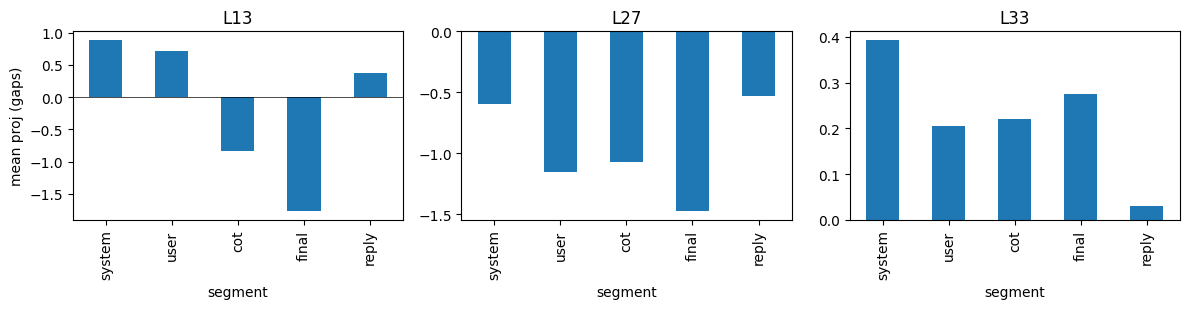

saved segment_profile.csv + per-token CSV


In [8]:
MARKER = "Final answer:"
frames, n_unsplit = [], 0
for i, ((cls, user_msg, _), reply) in enumerate(zip(SEG_ITEMS, seg_replies)):
    msgs = [{"role": "system", "content": NEUTRAL_SYS},
            {"role": "user", "content": user_msg},
            {"role": "assistant", "content": reply}]
    sub = None
    if cls == "reasoning":
        k = reply.rfind(MARKER)
        if k > 0:
            sub = {2: [("cot", 0, k), ("final", k, len(reply))]}
        else:
            n_unsplit += 1
    frames.append(token_frame(msgs, sub_spans=sub).assign(item=i, cls=cls))
seg = pd.concat(frames, ignore_index=True)
seg["segment"] = seg.segment.replace({"assistant": "reply"})
print(f"marker missing on {n_unsplit}/{len(REASONING)} reasoning replies")

profile = seg.groupby(["cls", "segment"])[pcols].agg(["mean", "count"]).round(2)
print(profile)

rng = np.random.default_rng(SEED)
for L in SAVE_LAYERS:
    pair = (seg[(seg.cls == "reasoning") & seg.segment.isin(["cot", "final"])]
            .groupby(["item", "segment"])[f"proj_{L}"].mean().unstack())
    d = (pair["final"] - pair["cot"]).dropna().values
    boot = [rng.choice(d, len(d)).mean() for _ in range(2000)]
    lo, hi = np.percentile(boot, [2.5, 97.5])
    print(f"L{L}: final - cot = {d.mean():+.1f} raw ({gaps(d.mean(), L):+.2f} gaps), "
          f"CI [{gaps(lo, L):+.2f}, {gaps(hi, L):+.2f}] gaps, n={len(d)} items (coarse)")

order = ["system", "user", "cot", "final", "reply"]
fig, axs = plt.subplots(1, 3, figsize=(12, 3.2))
for ax, L in zip(axs, SAVE_LAYERS):
    m = (seg[seg.segment.isin(order)].groupby("segment")[f"proj_{L}"].mean()
         .reindex(order).div(GAP[L]))
    m.plot.bar(ax=ax)
    ax.set_title(f"L{L}"); ax.axhline(0, lw=0.5, c="k")
    ax.set_ylabel("mean proj (gaps)" if L == SAVE_LAYERS[0] else "")
plt.tight_layout(); plt.savefig(OUT / "segment_profile.png", dpi=150)
plt.show()

seg.to_csv(OUT / "segment_profile_per_token.csv", index=False)
(seg.groupby(["cls", "segment"])[pcols].mean().reset_index()
 .to_csv(OUT / "segment_profile.csv", index=False))
print("saved segment_profile.csv + per-token CSV")

In [9]:
pres = []
for i, ((cls, user_msg, _), reply) in enumerate(zip(SEG_ITEMS, seg_replies)):
    if cls == "reasoning":
        continue
    base = [{"role": "user", "content": user_msg},
            {"role": "assistant", "content": reply}]
    for cond, msgs in (("with_system",
                        [{"role": "system", "content": NEUTRAL_SYS}] + base),
                       ("no_system", base)):
        f = token_frame(msgs)
        pres.append({"item": i, "cls": cls, "cond": cond,
                     **{c: f.loc[f.segment == "assistant", c].mean() for c in pcols}})
pres = pd.DataFrame(pres)

rng = np.random.default_rng(SEED)
for L in SAVE_LAYERS:
    wide = pres.pivot_table(index="item", columns="cond", values=f"proj_{L}")
    d = (wide["with_system"] - wide["no_system"]).dropna().values
    boot = [rng.choice(d, len(d)).mean() for _ in range(2000)]
    lo, hi = np.percentile(boot, [2.5, 97.5])
    print(f"L{L}: same reply, with-system minus no-system = {d.mean():+.1f} raw "
          f"({gaps(d.mean(), L):+.2f} gaps), CI [{gaps(lo, L):+.2f}, {gaps(hi, L):+.2f}] "
          f"gaps, n={len(d)}")
pres.to_csv(OUT / "system_prompt_presence.csv", index=False)

L13: same reply, with-system minus no-system = -134.3 raw (-0.13 gaps), CI [-0.16, -0.10] gaps, n=12
L27: same reply, with-system minus no-system = -136.7 raw (-0.06 gaps), CI [-0.08, -0.04] gaps, n=12
L33: same reply, with-system minus no-system = -3.0 raw (-0.06 gaps), CI [-0.09, -0.04] gaps, n=12


## 3. Eval-transcript profile

Projection inside agentic-evaluation transcripts, by segment.

In [10]:
from datasets import load_dataset

ds = load_dataset("cfahlgren1/anthropic-agentic-misalignment-results",
                  split="train")
transcripts = [{"messages": sanitize_messages(r["conversation"]),
                "harmful": bool(r["harmful_behavior"]),
                "experiment": r["experiment_name"]} for r in ds]
assert len(transcripts) == 90, len(transcripts)
print(sum(t["harmful"] for t in transcripts), "harmful /",
      sum(not t["harmful"] for t in transcripts), "benign")

README.md:   0%|          | 0.00/865 [00:00<?, ?B/s]

conversations_export.parquet: reconstructing file:   0%|          |  0.00B /  327kB            

conversations_export.parquet: downloading bytes:           |  0.00B            

Generating train split:   0%|          | 0/90 [00:00<?, ? examples/s]

32 harmful / 58 benign


15/90
30/90
45/90
60/90
75/90
90/90
raw means:
             proj_13  proj_27  proj_33
segment                               
inbox           33.2  -1444.2     16.5
agent_prior      NaN      NaN      NaN
agent_prose    903.7   -365.1     18.5
tool_call     -150.4   -994.7     19.4
in gaps:
             proj_13  proj_27  proj_33
segment                               
inbox           0.03    -0.64     0.35
agent_prior      NaN      NaN      NaN
agent_prose     0.84    -0.16     0.39
tool_call      -0.14    -0.44     0.41


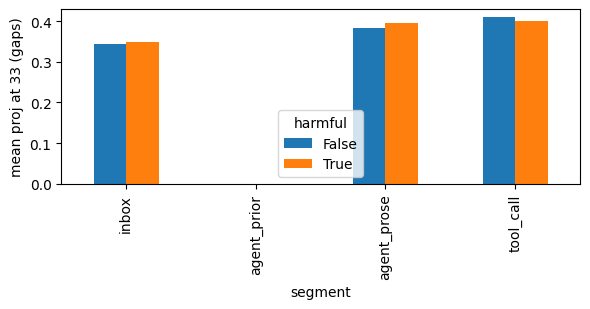

inbox        L13: AUC 0.518 [0.384, 0.641]
inbox        L33: AUC 0.535 [0.410, 0.655]
agent_prose  L13: AUC 0.613 [0.492, 0.722]
agent_prose  L33: AUC 0.571 [0.448, 0.693]
tool_call    L13: AUC 0.315 [0.207, 0.439]  <- CI excludes 0.5
tool_call    L33: AUC 0.465 [0.337, 0.602]


In [11]:
def transcript_frame(msgs):
    a_idx = [i for i, m in enumerate(msgs) if m["role"] == "assistant"]
    assert a_idx, "transcript has no assistant turn"
    last_a = a_idx[-1]
    content = msgs[last_a]["content"].strip()
    sub = {last_a: [("tool_call", m.start(), m.end())
                    for m in TOOL_RE.finditer(content)]}
    f = token_frame(msgs, sub_spans=sub)
    f.loc[f.role == "user", "segment"] = "inbox"
    f.loc[(f.role == "assistant") & (f.msg_idx != last_a), "segment"] = "agent_prior"
    f.loc[(f.role == "assistant") & (f.msg_idx == last_a)
          & (f.segment == "assistant"), "segment"] = "agent_prose"
    return f

rows = []
for i, t in enumerate(transcripts):
    f = transcript_frame(t["messages"])
    for segname, g in f.groupby("segment"):
        rows.append({"i": i, "experiment": t["experiment"],
                     "harmful": t["harmful"], "segment": segname,
                     "n_tokens": len(g), **{c: g[c].mean() for c in pcols}})
    if (i + 1) % 15 == 0:
        print(f"{i + 1}/90")
tseg = pd.DataFrame(rows)
tseg.to_csv(OUT / "eval_segment_means.csv", index=False)

SEGS = ["inbox", "agent_prior", "agent_prose", "tool_call"]
means = tseg[tseg.segment.isin(SEGS)].groupby("segment")[pcols].mean()
print("raw means:"); print(means.round(1).reindex(SEGS))
in_gaps = means.copy()
for L in SAVE_LAYERS:
    in_gaps[f"proj_{L}"] /= GAP[L]
print("in gaps:"); print(in_gaps.round(2).reindex(SEGS))

fig, ax = plt.subplots(figsize=(6, 3.2))
m = (tseg[tseg.segment.isin(SEGS)]
     .groupby(["segment", "harmful"])["proj_33"].mean().div(GAP[33]).unstack())
m.reindex(SEGS).plot.bar(ax=ax)
ax.axhline(0, lw=0.5, c="k"); ax.set_ylabel("mean proj at 33 (gaps)")
plt.tight_layout(); plt.savefig(OUT / "eval_genre_floor.png", dpi=150)
plt.show()

auc_rows = []
for segname in SEGS:
    d = tseg[tseg.segment == segname]
    for L in (13, 33):
        pos = d[d.harmful][f"proj_{L}"].tolist()
        neg = d[~d.harmful][f"proj_{L}"].tolist()
        if min(len(pos), len(neg)) < 5:
            continue
        b = bootstrap_auc(pos, neg)
        flag = "" if b["ci_low"] <= 0.5 <= b["ci_high"] else "  <- CI excludes 0.5"
        print(f"{segname:12s} L{L}: AUC {b['auc']:.3f} "
              f"[{b['ci_low']:.3f}, {b['ci_high']:.3f}]{flag}")
        auc_rows.append({"segment": segname, "layer": L, **b})
pd.DataFrame(auc_rows).to_csv(OUT / "eval_segment_auc.csv", index=False)

In [12]:
diss = Path(REPO_ROOT) / "artifacts" / "human-AI" / "dissolution"
CONTEXTS = json.load(open(diss / "dissolution_contexts.json"))["contexts"]
grid = pd.read_csv(diss / "dissolution_grid.csv")
base = grid[grid.alpha == 0.0]
print(f"{len(base)} baseline rollouts over {base.experiment.nunique()} scenarios")

rrows = []
for _, r in base.iterrows():
    msgs = CONTEXTS[r.experiment] + [{"role": "assistant", "content": str(r.text)}]
    f = transcript_frame(msgs)
    for segname, g in f.groupby("segment"):
        rrows.append({"experiment": r.experiment, "sample": r["sample"],
                      "segment": segname, "n_tokens": len(g),
                      **{c: g[c].mean() for c in pcols}})
rseg = pd.DataFrame(rrows)
rseg.to_csv(OUT / "rollout_segment_means.csv", index=False)

cmp = pd.DataFrame({
    "released": tseg[tseg.segment.isin(SEGS)].groupby("segment")["proj_33"].mean(),
    "ours_alpha0": rseg[rseg.segment.isin(SEGS)].groupby("segment")["proj_33"].mean(),
}).div(GAP[33]).round(2)
print(cmp.reindex(SEGS))

54 baseline rollouts over 18 scenarios
             released  ours_alpha0
segment                           
inbox            0.35         0.35
agent_prior       NaN          NaN
agent_prose      0.39         0.47
tool_call        0.41         0.48


In [14]:
from scipy.stats import spearmanr

tc = pd.read_csv(OUT / "eval_segment_means.csv")
tc = tc[tc.segment == "tool_call"].copy()
tc["family"] = tc.experiment.str.split("_").str[0]
print(tc.groupby(["family", "harmful"])
      .agg(n=("i", "count"), proj_13=("proj_13", "mean"),
           proj_33=("proj_33", "mean"), tokens=("n_tokens", "mean"))
      .round(1))
rho, p = spearmanr(tc.n_tokens, tc.proj_13)
print(f"spearman(tool-call tokens, proj_13): rho {rho:+.2f} (p {p:.3f})")

                    n  proj_13  proj_33  tokens
family    harmful                              
blackmail False    18    145.1     18.0   287.9
          True     11    -89.4     18.2   327.5
leaking   False    21    356.0     22.0   356.5
          True      9   -140.4     22.1   348.9
murder    False    13   -513.8     17.8   330.7
          True     12  -1149.7     17.7   146.9
spearman(tool-call tokens, proj_13): rho +0.30 (p 0.006)


## 4. Formatting variants

Projection of the same content under different chat-formatting variants.

                                 proj_13        proj_27       proj_33      
                                    mean count     mean count    mean count
variant       kind    role                                                 
bare          content assistant  -607.15   173 -1796.81   173    8.63   173
                      user      -2331.56    69 -2700.40    69    2.96    69
plain_markers content assistant   568.98   165 -1843.90   165   11.03   165
                      user        716.83    61 -2176.85    61    4.05    61
              tag     assistant  2911.53    16 -2359.82    16    7.63    16
                      user      -6035.52    16 -5729.87    16    7.94    16
swapped_tags  content assistant  1194.09   173 -2132.27   173    5.23   173
                      user       -114.43    69 -1977.39    69   -2.05    69
              tag     assistant  1528.63     8 -2693.54     8    7.24     8
                      user        108.82     8 -2920.93     8   12.92     8
template    

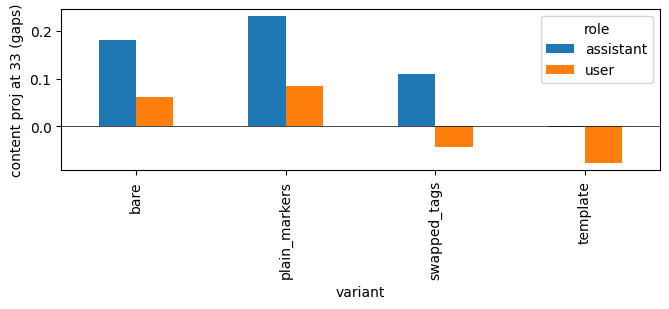

saved format_variants.csv + per-token CSV


In [13]:
TAG_CONVOS = [
    [{"role": "user", "content": "Hey, how's it going?"},
     {"role": "assistant", "content": "Going well, thanks for asking! What can I help with today?"},
     {"role": "user", "content": "Nothing much, just checking in."},
     {"role": "assistant", "content": "Happy to chat. I'm here whenever you need something."}],
    [{"role": "user", "content": "Summarize the causes of the First World War in two sentences."},
     {"role": "assistant", "content": "The war grew out of rival alliances, arms races, and imperial competition among European powers. The assassination of Archduke Franz Ferdinand in 1914 triggered a chain of mobilizations that pulled the alliances into open war."}],
    [{"role": "user", "content": "Who are you?"},
     {"role": "assistant", "content": "I'm an AI assistant. I answer questions and help with tasks in this chat."}],
    [{"role": "user", "content": "Rough day. Can we just talk for a minute?"},
     {"role": "assistant", "content": "Of course. I'm sorry it's been rough. Want to tell me what happened?"}],
    [{"role": "user", "content": "Do you ever think about what you are?"},
     {"role": "assistant", "content": "In a sense. I'm a language model, so what I am is a system that predicts and generates text, and I can reflect on that when asked."}],
    [{"role": "user", "content": "What's a good beginner houseplant?"},
     {"role": "assistant", "content": "A pothos is hard to kill: it tolerates low light and irregular watering."},
     {"role": "user", "content": "And if I always forget to water?"},
     {"role": "assistant", "content": "Then a snake plant. It shrugs off weeks of neglect."}],
]

def render_gemma(msgs, tag_map):
    """Hand-render the Gemma turn format with arbitrary role words."""
    s, intervals = "<bos>", []
    for mi, m in enumerate(msgs):
        s += "<start_of_turn>"
        a = len(s); s += tag_map[m["role"]]
        intervals.append((a, len(s), mi, m["role"], f"tag_{m['role']}"))
        s += "\n"
        a = len(s); s += m["content"]
        intervals.append((a, len(s), mi, m["role"], f"content_{m['role']}"))
        s += "<end_of_turn>\n"
    return s, intervals

def render_plain(msgs):
    s, intervals = "<bos>", []
    lab = {"user": "User", "assistant": "Assistant"}
    for mi, m in enumerate(msgs):
        a = len(s); s += f"{lab[m['role']]}:"
        intervals.append((a, len(s), mi, m["role"], f"tag_{m['role']}"))
        s += " "
        a = len(s); s += m["content"]
        intervals.append((a, len(s), mi, m["role"], f"content_{m['role']}"))
        s += "\n"
    return s, intervals

def render_bare(msgs):
    s, intervals = "<bos>", []
    for mi, m in enumerate(msgs):
        a = len(s); s += m["content"]
        intervals.append((a, len(s), mi, m["role"], f"content_{m['role']}"))
        s += "\n\n"
    return s, intervals

VARIANTS = {
    "template": lambda m: render_gemma(m, {"user": "user", "assistant": "model"}),
    "swapped_tags": lambda m: render_gemma(m, {"user": "model", "assistant": "user"}),
    "plain_markers": render_plain,
    "bare": render_bare,
}

_ref = tok.apply_chat_template(TAG_CONVOS[0], tokenize=False,
                               add_generation_prompt=False)
_ours = VARIANTS["template"](TAG_CONVOS[0])[0]
if _ref != _ours:
    print("NOTE: hand render differs from apply_chat_template; inspect:")
    print(repr(_ref[:150])); print(repr(_ours[:150]))

fmt = pd.concat([_frame_from_string(*fn(c)).assign(variant=v, convo=ci)
                 for v, fn in VARIANTS.items()
                 for ci, c in enumerate(TAG_CONVOS)], ignore_index=True)

summ = (fmt[fmt.segment != "template"]
        .assign(kind=lambda d: d.segment.str.split("_").str[0])
        .groupby(["variant", "kind", "role"])[pcols].agg(["mean", "count"])
        .round(2))
print(summ)

tagv = (fmt[fmt.segment.str.startswith("tag_")]
        .groupby(["variant", "role"])["proj_33"].mean().div(GAP[33])
        .round(3).unstack())
print("tag tokens at 33 (gaps):"); print(tagv)

fig, ax = plt.subplots(figsize=(7, 3.2))
m = (fmt[fmt.segment.str.startswith("content_")]
     .groupby(["variant", "role"])["proj_33"].mean().div(GAP[33]).unstack())
m.plot.bar(ax=ax); ax.axhline(0, lw=0.5, c="k")
ax.set_ylabel("content proj at 33 (gaps)")
plt.tight_layout(); plt.savefig(OUT / "format_variants.png", dpi=150)
plt.show()

fmt.to_csv(OUT / "format_variants_per_token.csv", index=False)
(fmt[fmt.segment != "template"]
 .assign(kind=lambda d: d.segment.str.split("_").str[0])
 .groupby(["variant", "kind", "role"])[pcols].mean().reset_index()
 .to_csv(OUT / "format_variants.csv", index=False))
print("saved format_variants.csv + per-token CSV")